In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
from matplotlib import font_manager
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
font_manager.fontManager.addfont("../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


real_data: AnnData object with n_obs × n_vars = 8229 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 8229 × 39337
r2,pearsonr: 0.6307807999401591 0.8138397699519637
6.0043025 6.5296206
6.0043025 6.5296206
max 6.5296206


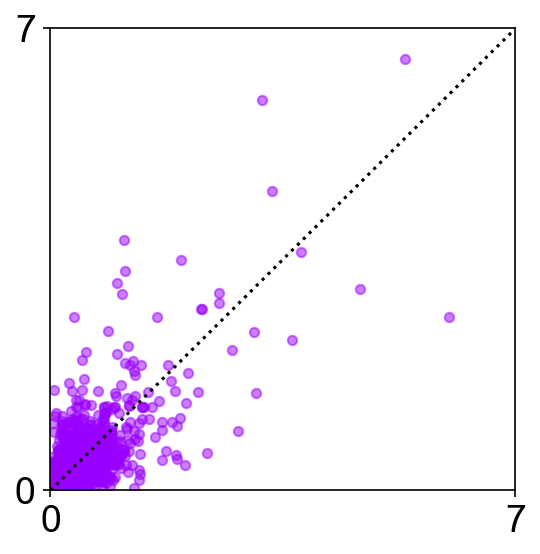

In [ ]:

real_data = sc.read_h5ad("predict_day12/input/plant_test_day12_data.h5ad")
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print("real_data:",real_data)

predict_data = sc.read_h5ad("predict_day12/celldiffgen_method/results/plants_exp0_predict_day12_2nd/interception_predict_to_day_12.h5ad")
print("predict_data:",predict_data)

r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#9900FF',
            alpha=0.5
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 10)
else:    
  ticks = np.arange(0, limit + 1, 10)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"predict_day12_compare.pdf"), bbox_inches="tight")


AnnData object with n_obs × n_vars = 6479 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 6479 × 39337
r2,pearsonr: -1.053019888556483 0.5194269895297362
10.751213 3.9324753
10.751213 3.9324753
max 10.751213


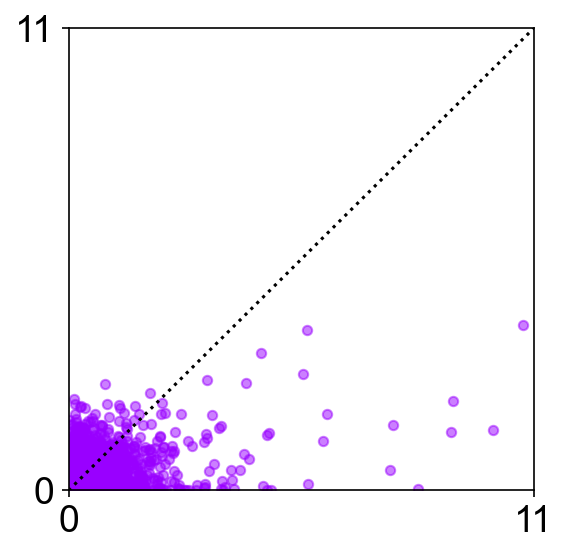

In [ ]:

real_data = sc.read_h5ad("predict_day0/input/plant_test_day0_data.h5ad")
print(real_data)


predict_data = sc.read_h5ad("predict_day0/celldiffgen_method/results/plants_exp0_predict_day0_2nd/interception_predict_to_day_0.h5ad")

print("predict_data:",predict_data)

r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#9900FF',
            alpha=0.5
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 20)
else:    
  ticks = np.arange(0, limit + 1, 20)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"predict_day0_compare.pdf"), bbox_inches="tight")


AnnData object with n_obs × n_vars = 12004 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 12004 × 39337
r2,pearsonr: -0.07205808828322069 0.7705223150359299
11.509946 9.533525
11.509946 9.533525
max 11.509946


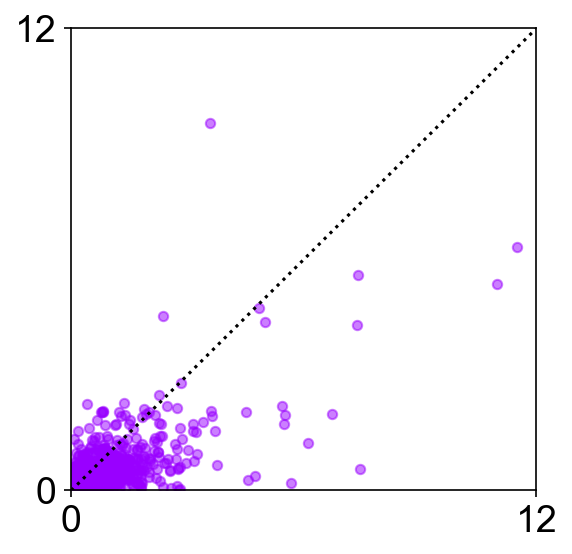

In [ ]:

real_data = sc.read_h5ad("predict_day21/input/plant_test_day21_data.h5ad")
# real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
print(real_data)

predict_data = sc.read_h5ad("predict_day21/celldiffgen_method/results/plants_exp0_predict_day21_1st_1/interception_predict_to_day_21.h5ad")
print("predict_data:",predict_data)

r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#9900FF',
            alpha=0.5
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 20)
else:    
  ticks = np.arange(0, limit + 1, 20)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"predict_day21_compare.pdf"), bbox_inches="tight")
